In [1]:
import numpy as np
import matplotlib.pyplot as plt
from accuracy_bounds.regressionproblems.feasible_sets import feasible_sets_features_nnx, feasible_sets_features_nn_xy
from accuracy_bounds.regressionproblems.kersize_compute import compute_kernel_size

# Create 2d meshgrid and surface data

In [2]:
def noisy_meshgrid_2d_regression(bounds: float, n_sqrt_mesh: int, input_noise: float):
    """
    Generate a 2D meshgrid for regression tasks.
    """
    
    # Create grid
    x = np.linspace(-bounds, bounds, n_sqrt_mesh)
    y = np.linspace(-bounds, bounds, n_sqrt_mesh)
    X, Y = np.meshgrid(x, y)

    # Noise levels
    input_noise = input_noise

    # Add noise to inputs
    X_noisy = X + input_noise * np.random.randn(*X.shape)
    Y_noisy = Y + input_noise * np.random.randn(*Y.shape)

    return X_noisy, Y_noisy

def sin_sqrt_surface_from_meshgrid(X: np.array, Y: np.array, output_noise: float):
    """
    Compute a surface from the given meshgrid.
    """

    R = np.divide(np.sqrt(X**2 + Y**2),0.9)
    F_clean = 0.5*np.sin(1+R)  

    # Add noise to output
    F_noisy = F_clean + output_noise * np.random.randn(*F_clean.shape)

    return F_noisy

Text(0.5, 0.92, 'sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

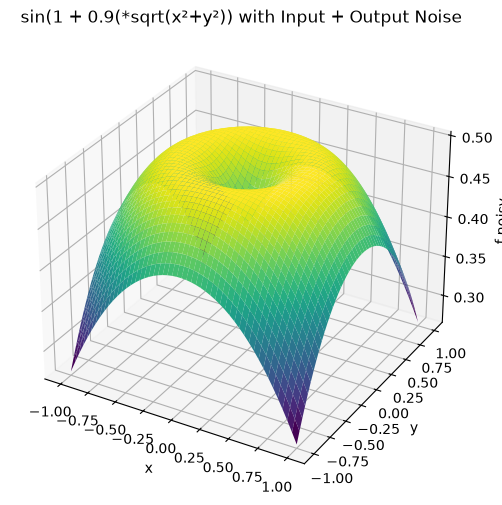

In [3]:

# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.0
output_noise = 0.0

# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
F_noisy = sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise) 

# Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_noisy, Y_noisy, F_noisy, cmap='viridis', edgecolor='none')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f noisy')
ax.set_title('sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

#plt.tight_layout()
#plt.show()

## Visualize noisy surface

Text(0.5, 0.92, 'sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

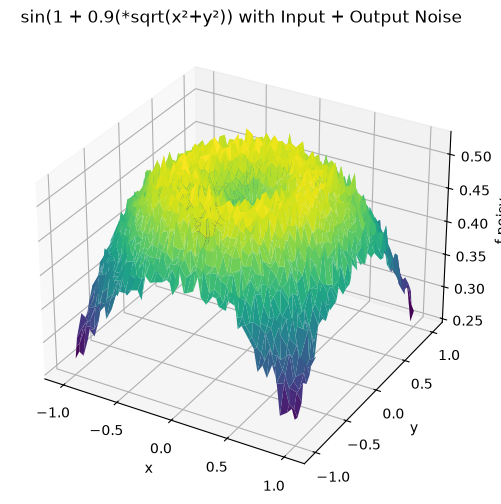

In [20]:
# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.01
output_noise = 0.01

# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
F_noisy = sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise) 

# Plot
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_noisy, Y_noisy, F_noisy, cmap='viridis', edgecolor='none')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f noisy')
ax.set_title('sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

#plt.tight_layout()
#plt.show()

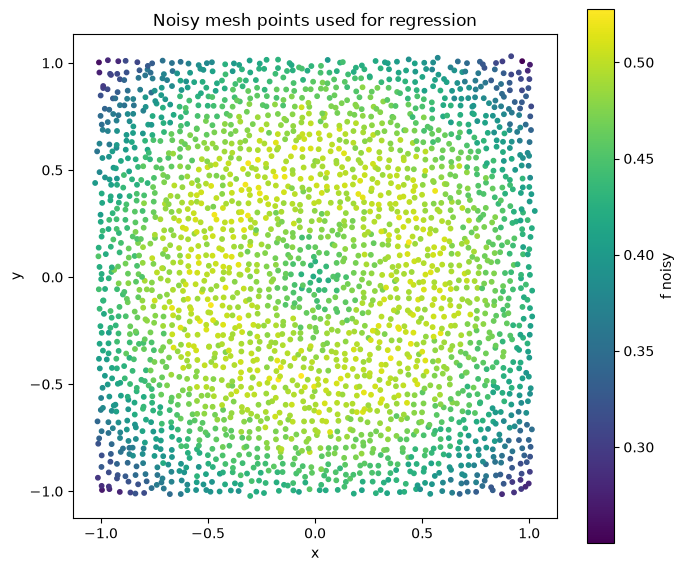

In [21]:
# Plot mesh points used for regression
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    X_noisy.ravel(),
    Y_noisy.ravel(),
    s=10,
    c=F_noisy.ravel(),
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Noisy mesh points used for regression")

cbar = plt.colorbar(ax.collections[0], ax=ax)
cbar.set_label("f noisy")

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Create noisy data

In [5]:
# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
tuples_input = np.vstack([X_noisy.ravel(), Y_noisy.ravel()]).T # sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise))

tuples_target = [sin_sqrt_surface_from_meshgrid(x, y, output_noise) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]
tuples_target = np.asarray(tuples_target).reshape(-1, 1)

final_tuples = [(np.array([x, y]), sin_sqrt_surface_from_meshgrid(x, y, output_noise)) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]

In [27]:
print(np.shape(X_noisy))

(50, 50)


## Construct feasible sets

In [6]:
result_feas= feasible_sets_features_nn_xy(tuples_input,tuples_target, N_max=300, qx=0.1, tau_y=0.01, ext_D = True)

In [ ]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])
print("average kernelsize", kersize)


average kernelsize 0.005980308660367043


## Regressors trained to approximate function 


In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF,
    ConstantKernel,
    WhiteKernel,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
)

In [9]:
X = tuples_input                          # (N,2)
y = tuples_target.ravel()                 # (N,)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.7,
    random_state=42,
)

In [23]:
y_trainf = np.asarray(y_train).reshape(-1, 1)
result_feas_train= feasible_sets_features_nn_xy(X_train,y_trainf, N_max=300, qx=0.1, tau_y=0.01, ext_D = True)

In [24]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas_train["feasible_sets"])
print("average kernelsize train", kersize)


average kernelsize train 0.007932093841504867


In [25]:
y_testf = np.asarray(y_test).reshape(-1, 1)
result_feas_test= feasible_sets_features_nn_xy(X_test,y_testf, N_max=300, qx=0.1, tau_y=0.01, ext_D = True)

In [26]:
kersize, M_prime, Nk_stats = compute_kernel_size(result_feas["feasible_sets"])
print("average kernelsize test", kersize)


average kernelsize test 0.005980308660367043


### MLP Regressor

In [10]:
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(128, 128),
        activation="relu",
        solver="adam",
        learning_rate_init=1e-3,
        max_iter=5000,
        random_state=42,
    ))
])

mlp.fit(X_train, y_train)

y_pred_mlp = mlp.predict(X_test)

print("MLP")
print("RMSE =", np.sqrt(mean_squared_error(y_test, y_pred_mlp)))
print("R²   =", r2_score(y_test, y_pred_mlp))

MLP
RMSE = 0.01748716851721411
R²   = 0.8663816257609616


### Gaussian process regressor

In [11]:
kernel = (
    ConstantKernel(1.0, (1e-3, 1e3))
    * RBF(length_scale=0.2, length_scale_bounds=(1e-3, 10))
    + WhiteKernel(noise_level=1e-4)
)

gpr = Pipeline([
    ("scaler", StandardScaler()),
    ("gpr", GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=5,
        random_state=42,
    ))
])

gpr.fit(X_train, y_train)

y_pred_gpr = gpr.predict(X_test)

print("\nGaussian Process")
print("RMSE =", np.sqrt(mean_squared_error(y_test, y_pred_gpr)))
print("R²   =", r2_score(y_test, y_pred_gpr))


Gaussian Process
RMSE = 0.010869087543828254
R²   = 0.9483805507676826


In [12]:
grid = np.column_stack([X_noisy.ravel(), Y_noisy.ravel()])

F_mlp = mlp.predict(grid).reshape(X_noisy.shape)
F_gpr = gpr.predict(grid).reshape(X_noisy.shape)

### Plot MLP prediction

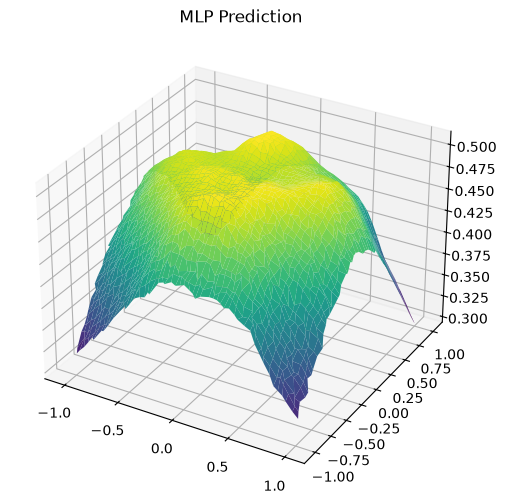

In [13]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X_noisy,
    Y_noisy,
    F_mlp,
    cmap="viridis",
    edgecolor="none",
)

ax.set_title("MLP Prediction")
plt.show()

### Plot GP prediction

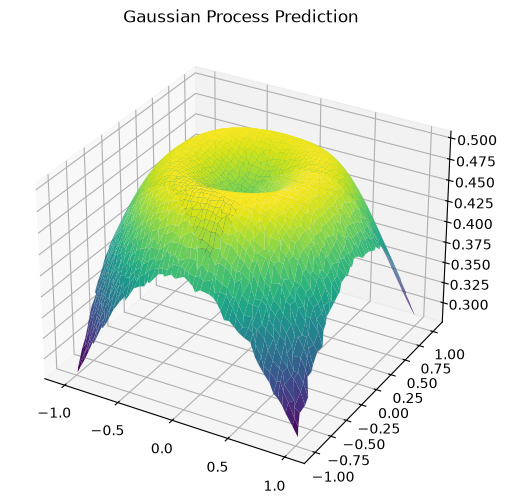

In [14]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X_noisy,
    Y_noisy,
    F_gpr,
    cmap="viridis",
    edgecolor="none",
)

ax.set_title("Gaussian Process Prediction")
plt.show()

In [15]:
gpr_model = gpr.named_steps["gpr"]
scaler = gpr.named_steps["scaler"]

X_scaled = scaler.transform(grid)

mean, std = gpr_model.predict(X_scaled, return_std=True)

mean = mean.reshape(X_noisy.shape)
std = std.reshape(X_noisy.shape)

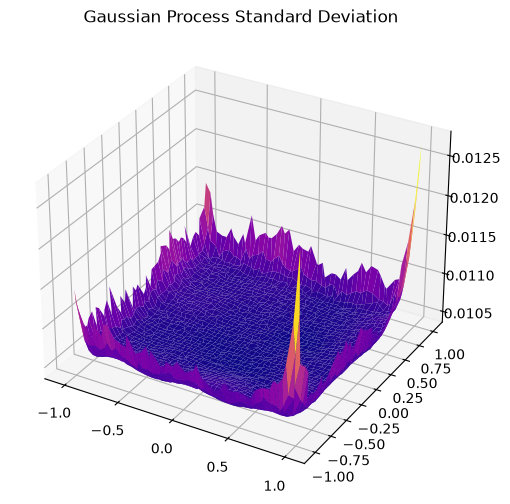

In [16]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X_noisy,
    Y_noisy,
    std,
    cmap="plasma",
    edgecolor="none",
)

ax.set_title("Gaussian Process Standard Deviation")
plt.show()

## Evaluate MLP and GP on extended dataset constructed with feasible sets

In [17]:
D_prime = result_feas["D_prime"]

X_prime = np.vstack([x for x, y in D_prime])
y_prime = np.asarray([y for x, y in D_prime]).ravel()

print(X_prime.shape)
print(y_prime.shape)

(636126, 2)
(636126,)


In [18]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# MLP
yhat_mlp = mlp.predict(X_prime)

print("MLP on D'")
print("RMSE :", np.sqrt(mean_squared_error(y_prime, yhat_mlp)))
print("MAE  :", mean_absolute_error(y_prime, yhat_mlp))
print("R²   :", r2_score(y_prime, yhat_mlp))

# GP
yhat_gp = gpr.predict(X_prime)

print("\nGP on D'")
print("RMSE :", np.sqrt(mean_squared_error(y_prime, yhat_gp)))
print("MAE  :", mean_absolute_error(y_prime, yhat_gp))
print("R²   :", r2_score(y_prime, yhat_gp))

MLP on D'
RMSE : 0.01721232272088987
MAE  : 0.013360639534850454
R²   : 0.7326368508530292

GP on D'
RMSE : 0.010955859335738337
MAE  : 0.008686482192068506
R²   : 0.891678296137788
